# 05 · Final model report figures

Figures for the report, from the final model `xgb_v3` on the test months of the rolling-origin backtest (`make backtest`).

The model is frozen, so nothing in this notebook is used to choose anything.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from negprice.config import FIGURES_DIR, PROCESSED_DATA_DIR, REGIONS

FINAL = "xgb_v3"

preds = pd.read_parquet(PROCESSED_DATA_DIR / "backtest_predictions.parquet")
final = preds[(preds["model"] == FINAL) & preds["scored"]]
print(f"{FINAL}: {len(final):,} scorable test half-hours, {final['fold'].nunique()} folds")

xgb_v3: 157,824 scorable test half-hours, 36 folds


## 1. Reliability of the final model on the test months

**Why:** a probability forecast should mean what it says: of the half-hours given about 30%, about 30% should turn out negative. Same method as the validation check in notebook 04 (section 4): 10 bands of 10 points of predicted probability; per band, mean predicted probability vs share actually negative, per region. Here on the test months, with the predictions the backtest scored.

In [2]:
final = final.assign(band=pd.cut(final["prob"], np.linspace(0, 1, 11), include_lowest=True))

reliability = final.groupby(["REGIONID", "band"], observed=True).agg(
    n=("prob", "size"),
    mean_prob=("prob", "mean"),
    share_neg=("is_neg", "mean"),
)
reliability["diff_pts"] = (reliability["mean_prob"] - reliability["share_neg"]) * 100
reliability.loc[REGIONS].round({"mean_prob": 3, "share_neg": 3, "diff_pts": 1})

n  mean_prob  share_neg  diff_pts
REGIONID band                                                
SA1      (-0.001, 0.1]  30036      0.018      0.011       0.6
         (0.1, 0.2]      3103      0.144      0.131       1.3
         (0.2, 0.3]      1939      0.247      0.209       3.8
         (0.3, 0.4]      1485      0.349      0.327       2.2
         (0.4, 0.5]      1477      0.452      0.425       2.7
         (0.5, 0.6]      1509      0.551      0.519       3.2
         (0.6, 0.7]      1754      0.651      0.633       1.9
         (0.7, 0.8]      2372      0.753      0.759      -0.7
         (0.8, 0.9]      3368      0.853      0.889      -3.6
         (0.9, 1.0]      5565      0.960      0.983      -2.3
VIC1     (-0.001, 0.1]  31918      0.016      0.009       0.7
         (0.1, 0.2]      3182      0.144      0.109       3.5
         (0.2, 0.3]      1909      0.248      0.210       3.8
         (0.3, 0.4]      1569      0.349      0.298       5.1
         (0.4, 0.5]      1436      0.450      0.421       2.8
         (0.5, 0.6]      1451      0.551      0.485       6.6
         (0.6, 0.7]      1509      0.650      0.611       3.9
         (0.7, 0.8]      1874      0.752      0.729       2.3
         (0.8, 0.9]      2566      0.855      0.855       0.1
         (0.9, 1.0]      5194      0.960      0.966      -0.5
NSW1     (-0.001, 0.1]  43442      0.010      0.009       0.0
         (0.1, 0.2]      2337      0.146      0.158      -1.3
         (0.2, 0.3]      1404      0.247      0.245       0.2
         (0.3, 0.4]       978      0.349      0.366      -1.7
         (0.4, 0.5]       816      0.449      0.473      -2.4
         (0.5, 0.6]       750      0.548      0.600      -5.2
         (0.6, 0.7]       696      0.650      0.614       3.6
         (0.7, 0.8]       679      0.751      0.758      -0.7
         (0.8, 0.9]       735      0.853      0.844       0.9
         (0.9, 1.0]       771      0.948      0.938       1.1

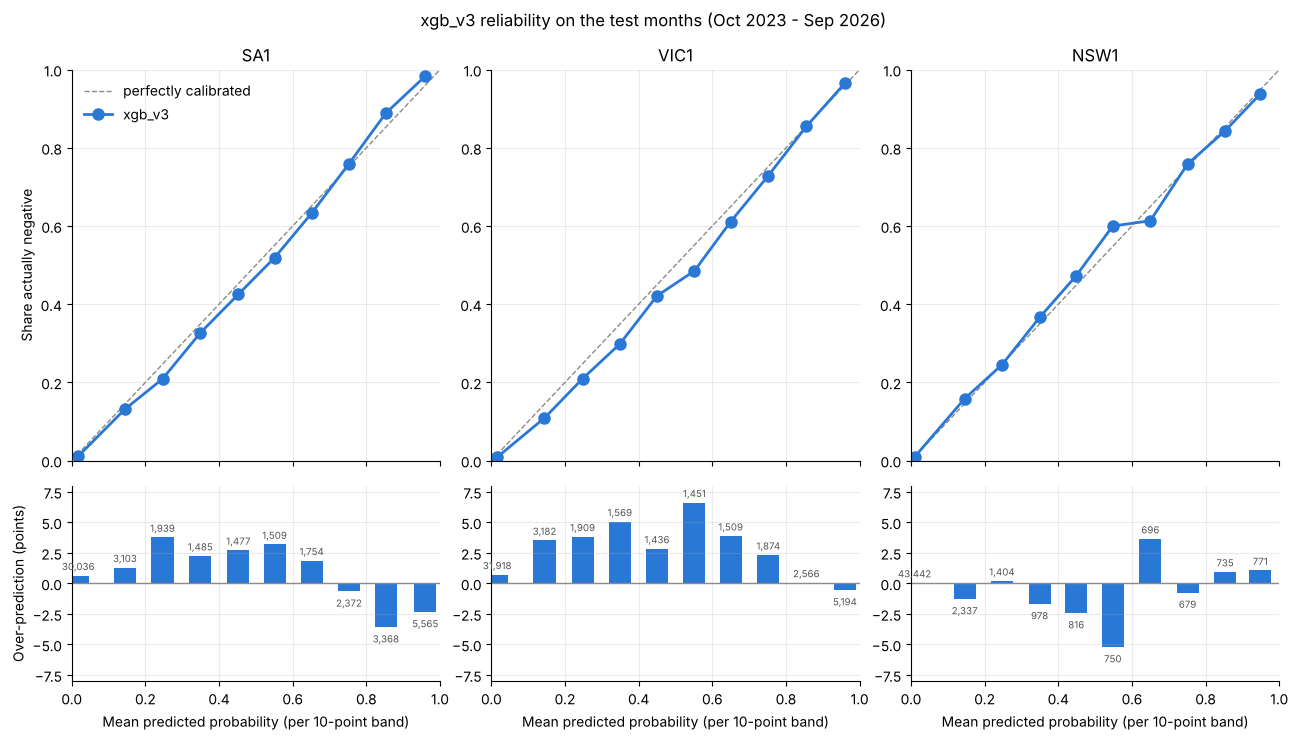

In [3]:
BLUE, GREY = "#2a78d6", "#8c8b85"
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})
for i, region in enumerate(REGIONS):
    r = reliability.loc[region]
    top, bottom = axes[0, i], axes[1, i]

    top.plot([0, 1], [0, 1], ls="--", lw=1, color=GREY, label="perfectly calibrated")
    top.plot(r["mean_prob"], r["share_neg"], marker="o", ms=8, lw=2, color=BLUE, label=FINAL)
    top.set_title(region)
    top.set_ylim(0, 1)
    top.set_ylabel("Share actually negative" if i == 0 else "")

    bottom.axhline(0, lw=1, color=GREY)
    bottom.bar(r["mean_prob"], r["diff_pts"], width=0.06, color=BLUE)
    for x, d, n in zip(r["mean_prob"], r["diff_pts"], r["n"]):
        bottom.annotate(f"{n:,}", (x, d), xytext=(0, 4 if d >= 0 else -11),
                        textcoords="offset points", ha="center", fontsize=7, color="#555")
    bottom.set_xlabel("Mean predicted probability (per 10-point band)")
    bottom.set_ylabel("Over-prediction (points)" if i == 0 else "")

lim = np.ceil(reliability["diff_pts"].abs().max()) + 1
for ax in axes[1]:
    ax.set_ylim(-lim, lim)
for ax in axes.flat:
    ax.set_xlim(0, 1)
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].legend(frameon=False, loc="upper left")
fig.suptitle(f"{FINAL} reliability on the test months (Oct 2023 - Sep 2026)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "reliability_final_model_test.png", dpi=150, bbox_inches="tight")
plt.show()

**Result:** 

## 2. Same scored rows for every model

**Why:** a comparison between models is only fair if every model is scored on exactly the same half-hours, with the same labels and the same folds. Reference: `aemo_recal`.

In [ ]:
TABLE_MODELS = ["baseline", "aemo_raw", "aemo_recal", "xgb_v3", "chronos_price", "chronos_cov"]
KEYS = ["REGIONID", "HH_END"]

present = set(preds["model"].unique())
assert set(TABLE_MODELS) <= present, f"missing models: {set(TABLE_MODELS) - present}"

ref = preds[preds["model"] == "aemo_recal"].set_index(KEYS).sort_index()
checks = []
for m in TABLE_MODELS:
    d = preds[preds["model"] == m].set_index(KEYS).sort_index()
    same_rows = d.index.equals(ref.index)
    checks.append({
        "model": m,
        "rows": len(d),
        "same_rows": same_rows,
        "duplicates": int(d.index.duplicated().sum()),
        "missing_prob": int(d["prob"].isna().sum()),
        "same_labels": same_rows and bool((d["is_neg"] == ref["is_neg"]).all()),
        "same_folds": same_rows and bool((d["fold"] == ref["fold"]).all()),
        "same_scored": same_rows and bool((d["scored"] == ref["scored"]).all()),
    })
checks = pd.DataFrame(checks).set_index("model")
ok = (checks[["same_rows", "same_labels", "same_folds", "same_scored"]].all(axis=1)
      & (checks["duplicates"] == 0) & (checks["missing_prob"] == 0))
assert ok.all(), "models are not scored on identical rows"
checks

## 3. Where the models differ: by hour block and by season

**Why:** the pooled table gives one number per model and region. These two tables show whether a model's gain is spread out or concentrated, by hour block (night, morning, midday, evening; fixed local clock hours) and, separately, by season (summer Dec–Feb, autumn Mar–May, winter Jun–Aug, spring Sep–Nov). They are descriptive only: nothing here is used to choose anything.

**Method:** per region and cell, Brier, AUC, and Brier skill score against `aemo_recal` (and against `xgb_v3` for the Chronos models). Uncertainty as for the headline: monthly paired differences d = Brier(reference) − Brier(model) on identical rows (d > 0 means the model is better), wins out of the months in the cell, and a 95% percentile bootstrap interval of the mean d (10,000 resamples of the months).

**Caveats:** a block cell pools all 36 months; a season cell holds only 9 months, so its intervals are wide. Cells with very few negatives (NSW at night) give unstable AUC and skill scores.

In [ ]:
from sklearn.metrics import roc_auc_score

from negprice.config import REPORTS_DIR

BACKTEST_DIR = REPORTS_DIR / "backtest"
N_BOOT = 10_000
rng = np.random.default_rng(0)

s = preds[preds["scored"] & preds["model"].isin(TABLE_MODELS)].copy()
s["se"] = (s["prob"] - s["is_neg"]) ** 2


def boot_ci(d):
    means = d[rng.integers(0, len(d), (N_BOOT, len(d)))].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


def breakdown(by):
    rows = []
    for (region, cell), g in s.groupby(["REGIONID", by]):
        monthly = g.groupby(["model", "fold"])["se"].mean().unstack("model")
        brier = g.groupby("model")["se"].mean()
        for m, gm in g.groupby("model"):
            row = {"REGIONID": region, by: cell, "model": m, "n": len(gm),
                   "share_neg": gm["is_neg"].mean(), "mean_prob": gm["prob"].mean(),
                   "brier": brier[m],
                   "auc": roc_auc_score(gm["is_neg"], gm["prob"]) if gm["is_neg"].nunique() == 2 else np.nan}
            refs = ["aemo_recal"] + (["xgb_v3"] if m.startswith("chronos") else [])
            for ref in refs:
                if m == ref:
                    continue
                d = (monthly[ref] - monthly[m]).to_numpy()
                lo, hi = boot_ci(d)
                tag = "recal" if ref == "aemo_recal" else ref
                row[f"bss_vs_{tag}"] = 1 - brier[m] / brier[ref]
                row[f"wins_vs_{tag}"] = int((d > 0).sum())
                row[f"months_vs_{tag}"] = len(d)
                row[f"d_vs_{tag}"] = d.mean()
                row[f"ci_low_vs_{tag}"] = lo
                row[f"ci_high_vs_{tag}"] = hi
            rows.append(row)
    return pd.DataFrame(rows)


by_block = breakdown("block")
by_season = breakdown("season")
by_block.to_csv(BACKTEST_DIR / "oneway_by_block.csv", index=False)
by_season.to_csv(BACKTEST_DIR / "oneway_by_season.csv", index=False)
print(f"block cells: {len(by_block)}, season cells: {len(by_season)}")

Consistency check: the block numbers must match the harness's own `by_block.csv`.

In [ ]:
harness = pd.read_csv(BACKTEST_DIR / "by_block.csv")
merged = by_block.merge(harness, on=["model", "REGIONID", "block"], suffixes=("", "_harness"))
assert len(merged) == len(by_block), "some block cells are missing from by_block.csv"
for col in ["n", "brier", "bss_vs_recal"]:
    diff = (merged[col] - merged[f"{col}_harness"]).abs().max()
    print(f"{col}: max abs difference {diff:.2e}")
    assert diff < 1e-9, f"{col} differs from by_block.csv"

### Skill score against `aemo_recal` (%)

In [ ]:
ORDER = {"block": ["night", "morning", "midday", "evening"],
         "season": ["summer", "autumn", "winter", "spring"]}
COLS = ["baseline", "aemo_raw", "chronos_price", "chronos_cov", "xgb_v3"]


def bss_table(t, by):
    out = (t.pivot_table(index=["REGIONID", by], columns="model", values="bss_vs_recal") * 100)[COLS]
    idx = pd.MultiIndex.from_product([REGIONS, ORDER[by]], names=["REGIONID", by])
    return out.reindex(idx).round(1)


display(bss_table(by_block, "block"))
display(bss_table(by_season, "season"))

### `xgb_v3` against `aemo_recal`: monthly paired differences

In [ ]:
def paired(t, by, model, tag):
    cols = ["REGIONID", by, f"bss_vs_{tag}", f"wins_vs_{tag}", f"months_vs_{tag}",
            f"d_vs_{tag}", f"ci_low_vs_{tag}", f"ci_high_vs_{tag}"]
    out = t.loc[t["model"] == model, cols].copy()
    out[f"bss_vs_{tag}"] *= 100
    out[[f"wins_vs_{tag}", f"months_vs_{tag}"]] = out[[f"wins_vs_{tag}", f"months_vs_{tag}"]].astype(int)
    out[by] = pd.Categorical(out[by], ORDER[by], ordered=True)
    out["REGIONID"] = pd.Categorical(out["REGIONID"], REGIONS, ordered=True)
    return out.sort_values(["REGIONID", by]).set_index(["REGIONID", by]).round(4)


display(paired(by_block, "block", "xgb_v3", "recal"))
display(paired(by_season, "season", "xgb_v3", "recal"))

### `chronos_cov` against `xgb_v3`: monthly paired differences

In [ ]:
display(paired(by_block, "block", "chronos_cov", "xgb_v3"))
display(paired(by_season, "season", "chronos_cov", "xgb_v3"))

**Result:**